In [50]:
# Compare MassDot overtime with Records Request (2020 - 2021)

import pandas as pd
massdot = pd.read_csv('../cleaned_data/ACLU_merged_cleaned.csv')
records = pd.read_csv('../cleaned_data/Records_merged_cleaned.csv')

In [51]:
# Common locations
most_common_locations = massdot['Location Name'].value_counts().head(5)

# Common offenses
most_common_offenses = massdot['Offense Description'].value_counts().head(5)

most_common_locations, most_common_offenses

(Location Name
 Boston        27943
 W Roxbury     23670
 Dorchester    20004
 S Boston      13353
 Roxbury       10384
 Name: count, dtype: int64,
 Offense Description
 STOP/YIELD, FAIL TO * c89 §9                              17876
 LIGHTS VIOLATION, MV * c90 §7                              6862
 INSPECTION/STICKER, NO * c90 §20                           5229
 SPEEDING RATE OF SPEED EXCEEDING POSTED LIMIT  c90 §17     4290
 CROSSWALK VIOLATION * c89 §11                              3825
 Name: count, dtype: int64)

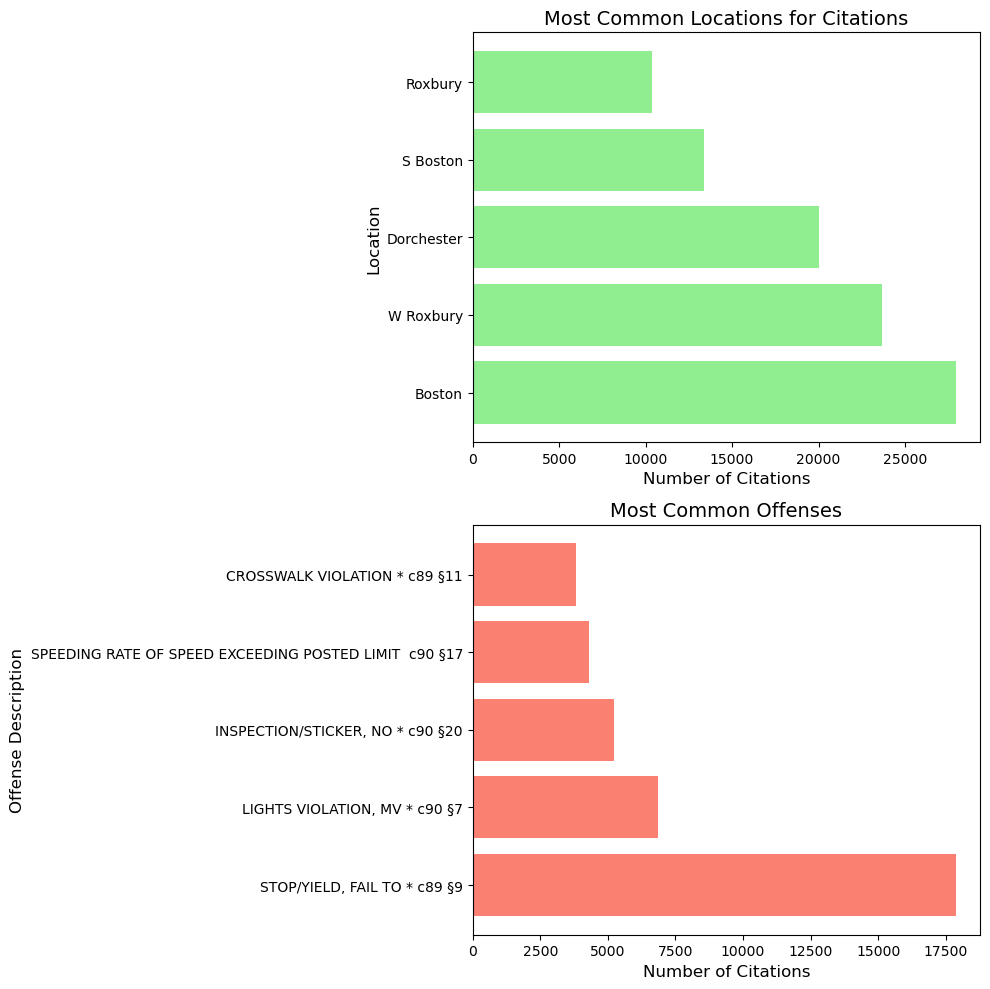

In [52]:
import matplotlib.pyplot as plt

# Set up the figure for subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Plot 2: Most common locations
axes[0].barh(most_common_locations.index, most_common_locations.values, color='lightgreen')
axes[0].set_title('Most Common Locations for Citations', fontsize=14)
axes[0].set_xlabel('Number of Citations', fontsize=12)
axes[0].set_ylabel('Location', fontsize=12)

# Plot 3: Most common offenses
axes[1].barh(most_common_offenses.index, most_common_offenses.values, color='salmon')
axes[1].set_title('Most Common Offenses', fontsize=14)
axes[1].set_xlabel('Number of Citations', fontsize=12)
axes[1].set_ylabel('Offense Description', fontsize=12)

# Adjust layout
plt.tight_layout()
plt.show()


In [53]:
# Plot foor the number of citations per hour of the day

# import pandas as pd
# import matplotlib.pyplot as plt

# # Ensure 'Military Time' is in the correct format
# massdot['Military Time'] = pd.to_datetime(massdot['Military Time'], format='%H:%M', errors='coerce').dt.hour

# # Drop rows with NaT values in 'Military Time'
# massdot = massdot.dropna(subset=['Military Time'])

# # Group by hour and calculate the number of citations
# citations_per_hour = massdot.groupby('Military Time').size()

# # Plot the number of citations per hour
# plt.figure(figsize=(15, 5))
# citations_per_hour.plot(kind='bar', color='skyblue')
# plt.title('Number of Citations per Hour', fontsize=16)
# plt.xlabel('Hour of Day (Military Time)', fontsize=14)
# plt.ylabel('Number of Citations', fontsize=14)
# plt.xticks(rotation=0)
# plt.grid(axis='y', alpha=0.75)
# plt.show()

In [54]:
# Print the head of massdot
massdot.head()

,Agency Code,Issuing Agency,Officer Id,Citation #,Type,Event/Written Date,Time-HH,Time-MM,AM-PM,Location Name,Offense,Offense Description,Race,Gender,Military Time
0,PD_BPH,Boston Police District C-11,131215,608180AA,WARN,2020-01-01,7,10,AM,Boston,8980,"YIELD AT INTERSECTION, FAIL * c89 §8",ASIAN,MALE,07:10
1,CP_BPX,Boston Police Special OPS,11735,R8170781,CIVIL,2020-01-01,12,45,AM,Boston,894A0,MARKED LANES VIOLATION * c89 §4A,MIDEST,MALE,00:45
2,CP_BPX,Boston Police Special OPS,11735,R8170782,CIVIL,2020-01-01,1,25,AM,Jamaica Plain,8940,"KEEP RIGHT ON HILL/OBSTRUCTED VIEW, FL * c89 §4",BLACK,MALE,01:25
3,PD_BPL,Boston Police District E-18,108874,T1573831,WARN,2020-01-01,4,45,PM,W Roxbury,907F0,MOTORCYCLE PASSENGER VIOLATION * c90 §7,BLACK,FEMALE,16:45
4,PD_BPC,Boston Police District B-3,11695,T1579403,CIVIL,2020-01-01,12,45,PM,Dorchester,909B0,UNREGISTERED MOTOR VEHICLE * c90 §9,BLACK,MALE,12:45


In [55]:
# Print the head of records
records.head()

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
0,8645.0,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,1/1/20,1200,1600,4.0,4.0
1,10738.0,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,1/1/20,1600,1800,2.0,2.0
2,11554.0,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,1/1/20,1330,1430,1.0,1.0
3,9843.0,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,1600,0,8.0,8.0
4,113177.0,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,0,400,4.0,4.0


In [56]:
# Print the column types of masdot
massdot.dtypes

Agency Code            object
Issuing Agency         object
Officer Id             object
Citation #             object
Type                   object
Event/Written Date     object
Time-HH                 int64
Time-MM                 int64
AM-PM                  object
Location Name          object
Offense                object
Offense Description    object
Race                   object
Gender                 object
Military Time          object
dtype: object

In [57]:
# Convert the "STARTTIME" column in records to military time like 00:00
records['STARTTIME'] = records['STARTTIME'].astype(str)
records['Military Start Time'] = records['STARTTIME'].apply(lambda x: '00:00' if x == '0' else f"{x.zfill(4)[:2]}:{x.zfill(4)[2:]}")

# Convert the "ENDTIME" column in records to military time like 00:00
records['ENDTIME'] = records['ENDTIME'].astype(str)
records['Military End Time'] = records['ENDTIME'].apply(lambda x: '00:00' if x == '0' else f"{x.zfill(4)[:2]}:{x.zfill(4)[2:]}")

In [58]:
# Change "IDNO6" from a float64 to an object 8645.0 to 8645 using strip
records['IDNO6'] = records['IDNO6'].astype(str)
records['IDNO6'] = records['IDNO6'].apply(lambda x: x.strip('.0'))

In [59]:
# Reset the index of both dataframes
massdot = massdot.reset_index(drop=True)
records = records.reset_index(drop=True)

In [60]:
records.head()

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,STARTTIME,ENDTIME,WRKDHRS,OTHOURS,Military Start Time,Military End Time
0,8645,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,1/1/20,1200,1600,4.0,4.0,12:00,16:00
1,10738,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,1/1/20,1600,1800,2.0,2.0,16:00,18:00
2,11554,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,1/1/20,1330,1430,1.0,1.0,13:30,14:30
3,9843,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,1600,0,8.0,8.0,16:00,00:00
4,113177,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,0,400,4.0,4.0,00:00,04:00


In [61]:
massdot['Event/Written Date'] = pd.to_datetime(massdot['Event/Written Date'])
records['OTDATE'] = pd.to_datetime(records['OTDATE'], format='%m/%d/%y')

print(records['OTDATE'][0])
print(massdot['Event/Written Date'][0])
print(records['Military Start Time'][0])
print(massdot['Military Time'][0])
print(records['Military End Time'][0])

records['OTDATE'][0] == massdot['Event/Written Date'][0]

2020-01-01 00:00:00
2020-01-01 00:00:00
12:00
07:10
16:00


True

In [62]:
# import pandas as pd

# # Initialize an empty list to store matching observations
# matching_rows = []

# # Loop through the records and massdot dataframes
# j_start = 0  # Initialize the starting index for massdot

# for i in range(len(records)//1000):
#     for j in range(j_start, len(massdot)):
#         # Check if the date in records is after the date in massdot
#         if records['OTDATE'][i] > massdot['Event/Written Date'][j]:
#             j_start = j  # Save the current index to start from here in the next iteration
#             break  # Break the inner loop to move to the next record if the date condition fails
        
#         # Check if the dates match
#         if records['OTDATE'][i] == massdot['Event/Written Date'][j]:
#             # Check if the officer IDs match
#             if records['IDNO6'][i] == massdot['Officer Id'][j]:
#                 # Check if the Military Time in massdot falls within the range specified in records
#                 if records['Military Start Time'][i] <= massdot['Military Time'][j] <= records['Military End Time'][i]:
#                     # Add the matching observation to the list as a dictionary
#                     matching_rows.append({
#                         'Officer Id': massdot['Officer Id'][j],
#                         'OTDATE': records['OTDATE'][i],
#                         'Event/Written Date': massdot['Event/Written Date'][j],
#                         'Military Start Time': records['Military Start Time'][i],
#                         'Military Time': massdot['Military Time'][j],
#                         'Military End Time': records['Military End Time'][i]
#                     })

# # Convert the list of matching rows to a DataFrame
# quantum = pd.DataFrame(matching_rows, columns=['Officer Id', 'OTDATE', 'Event/Written Date', 'Military Start Time', 'Military Time', 'Military End Time'])
# quantum

In [63]:
# Testing components of the algorithm

print(massdot['Officer Id'][37])
print(records['IDNO6'][110])

print(records['Military Start Time'][110])
print(massdot['Military Time'][37])
print(records['Military End Time'][110])

i = 110
j = 37

if records['OTDATE'][i] == massdot['Event/Written Date'][j]:
    print("True")

if records['IDNO6'][i] == massdot['Officer Id'][j]:
    print("True")

if records['Military Start Time'][i] <= massdot['Military Time'][j] <= records['Military End Time'][i]:
    print("True")

56354
56354
16:00
16:15
23:45
True
True
True


In [ ]:
import pandas as pd

# Step 1: Filter the `massdot` DataFrame if you want to skip rows before `j_start`
massdot_filtered = massdot.iloc[0:]

# Step 2: Perform an inner merge to match by date and Officer Id
merged_df = pd.merge(
    massdot_filtered,
    records,
    left_on=['Event/Written Date', 'Officer Id'],
    right_on=['OTDATE', 'IDNO6'],
    suffixes=('_massdot', '_records')
)

# Step 3: Filter rows where Military Time in massdot is within the range specified in court
quantum = merged_df[
    (merged_df['Military Start Time'] <= merged_df['Military Time']) &
    (merged_df['Military Time'] <= merged_df['Military End Time'])
][[
    'Officer Id', 'OTDATE', 'Event/Written Date', 
    'Military Start Time', 'Military Time', 'Military End Time', 'Issuing Agency', 'ASSIGNED_DESC', 'Offense Description'
]]

# Reset the index for clean output
quantum = quantum.reset_index(drop=True)


In [65]:
quantum

,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time,Issuing Agency,ASSIGNED_DESC,Offense Description
0,56354,2020-01-01,2020-01-01,16:00,16:15,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
1,56354,2020-01-01,2020-01-01,16:00,18:07,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
2,56354,2020-01-01,2020-01-01,16:00,18:57,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
3,56354,2020-01-01,2020-01-01,16:00,19:04,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
4,56354,2020-01-01,2020-01-01,16:00,16:24,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
...,...,...,...,...,...,...,...,...,...
6934,144446,2021-12-30,2021-12-30,07:30,12:35,16:00,Boston Police District A-7,DISTRICT 07,NaN
6935,106745,2021-12-30,2021-12-30,07:30,08:41,16:00,Boston Police District B-2,DISTRICT 02,NaN
6936,126547,2021-12-30,2021-12-30,16:00,17:26,23:45,Boston Police District E-13,DISTRICT 13,NaN
6937,126547,2021-12-30,2021-12-30,16:00,17:26,23:45,Boston Police District E-13,DISTRICT 13,NaN


In [66]:
# Remove any duplicate rows
quantum = quantum.drop_duplicates()

# Reset the index if needed
quantum = quantum.reset_index(drop=True)

quantum

,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time,Issuing Agency,ASSIGNED_DESC,Offense Description
0,56354,2020-01-01,2020-01-01,16:00,16:15,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
1,56354,2020-01-01,2020-01-01,16:00,18:07,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
2,56354,2020-01-01,2020-01-01,16:00,18:57,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
3,56354,2020-01-01,2020-01-01,16:00,19:04,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
4,56354,2020-01-01,2020-01-01,16:00,16:24,23:45,Boston Police District C-6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
...,...,...,...,...,...,...,...,...,...
6343,11953,2021-12-29,2021-12-29,16:00,18:30,23:45,Boston Police District E-13,DISTRICT 07,NaN
6344,14446,2021-12-30,2021-12-30,07:30,12:35,16:00,Boston Police District A-7,STREET OUTREACH TEAM,NaN
6345,144446,2021-12-30,2021-12-30,07:30,12:35,16:00,Boston Police District A-7,DISTRICT 07,NaN
6346,106745,2021-12-30,2021-12-30,07:30,08:41,16:00,Boston Police District B-2,DISTRICT 02,NaN


In [69]:
quantum['Issuing Agency'] = quantum['Issuing Agency'].str.extract('(\d+)')
quantum['Issuing Agency'] = pd.to_numeric(quantum['Issuing Agency'], errors='coerce').astype('Int64')
quantum

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/var/folders/4y/r6rcgtbn03z_wwr8z4tjksgr0000gn/T/ipykernel_7648/1817264737.py:1: SyntaxWarning: invalid escape sequence '\d'
  quantum['Issuing Agency'] = quantum['Issuing Agency'].str.extract('(\d+)')


,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time,Issuing Agency,ASSIGNED_DESC,Offense Description
0,56354,2020-01-01,2020-01-01,16:00,16:15,23:45,6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
1,56354,2020-01-01,2020-01-01,16:00,18:07,23:45,6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
2,56354,2020-01-01,2020-01-01,16:00,18:57,23:45,6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
3,56354,2020-01-01,2020-01-01,16:00,19:04,23:45,6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
4,56354,2020-01-01,2020-01-01,16:00,16:24,23:45,6,DISTRICT 06,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
...,...,...,...,...,...,...,...,...,...
6343,11953,2021-12-29,2021-12-29,16:00,18:30,23:45,13,DISTRICT 07,NaN
6344,14446,2021-12-30,2021-12-30,07:30,12:35,16:00,7,STREET OUTREACH TEAM,NaN
6345,144446,2021-12-30,2021-12-30,07:30,12:35,16:00,7,DISTRICT 07,NaN
6346,106745,2021-12-30,2021-12-30,07:30,08:41,16:00,2,DISTRICT 02,NaN


In [70]:
# Define the mapping dictionary with all integer values and set others to 0
mapping = {
    'DISTRICT 06': 6,
    'DISTRICT 05': 5,
    'COURT UNIT': 0,
    'DISTRICT 11': 11,
    'DISTRICT 04': 4,
    'DISTRICT 02': 2,
    'DISTRICT 18': 18,
    'DISTRICT 07': 7,
    'E-5   DETECTIVES': 5,
    'B-3\xa0\xa0 DCU SQUAD': 3,
    'DISTRICT 01': 1,
    'CANINE UNIT': 0,
    'MOBILE OPERATIONS PATROL /SWAT': 0,
    'DISTRICT 03': 3,
    'AUTO THEFT UNIT': 0,
    'D-14 DETECTIVES': 14,
    'DISTRICT 14': 14,
    'DISTRICT 13': 13,
    'A-1   DETECTIVES': 1,
    'HOMICIDE UNIT': 0,
    'B-2\xa0\xa0 DCU SQUAD': 2,
    'STREET OUTREACH TEAM': 0,
    'B-2   DETECTIVES': 2,
    'CRIMES AGAINST CHILDREN': 0,
    'FIREARMS ANALYSIS UNIT': 0,
    'ACADEMY': 0,
    'E-18 DCU SQUAD': 18,
    'YOUTH VIOLENCE STRIKE FORCE': 0,
    'B-3   DETECTIVES': 3,
    'FIELD OPERATIONS GROUP': 0,
    'DIGNITARY PROTECTION UNIT': 0,
    'BICYCLE UNIT': 0,
    'C-11 DETECTIVES': 11,
    'CITYWIDE DCU SQ #2': 0,
    'E-18 DETECTIVES': 18,
    'E-5\xa0\xa0 DCU SQUAD': 5,
    'E-13 DETECTIVES': 13,
    'ELECTRICAL MAINTENANCE SECTION': 0,
    'CRIME SCENE RESPONSE UNIT': 0,
    'COMM. VEHICLE UNIT': 0,
    'CITYWIDE DCU SQ #1': 0,
    'EVIDENCE CONTROL UNIT': 0,
    'A-7\xa0\xa0 DCU SQUAD': 7,
    'CRIME LABORATORY UNIT': 0,
    'BUREAU OF COMMUNITY ENGAGEMENT': 0,
    'DOMESTIC VIOLENCE UNIT': 0,
    'A-7   DETECTIVES': 7,
    'FORENSIC DIVISION': 0,
    'C-6\xa0\xa0 DCU SQUAD': 6,
    'SPECIAL INVESTIGATION UNIT': 0,
    "DISTRICT ATTORNEY'S OFF.  UNIT": 0,
    'C-11 DCU SQUAD': 11,
    'BRIC ': 0,
    'EXPLOSIVE ORDNANCE UNIT': 0,
    'D-4   DETECTIVES': 4
}

# Replace the values in the 'ASSIGNED_DESC' column
quantum['ASSIGNED_DESC'] = quantum['ASSIGNED_DESC'].replace(mapping)

# If ASSIGNED_DESC is not an integer, replace it with 0
quantum['ASSIGNED_DESC'] = pd.to_numeric(quantum['ASSIGNED_DESC'], errors='coerce').fillna(0).astype(int)

# Display the updated DataFrame
quantum

/var/folders/4y/r6rcgtbn03z_wwr8z4tjksgr0000gn/T/ipykernel_7648/656119389.py:61: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  quantum['ASSIGNED_DESC'] = quantum['ASSIGNED_DESC'].replace(mapping)


,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time,Issuing Agency,ASSIGNED_DESC,Offense Description
0,56354,2020-01-01,2020-01-01,16:00,16:15,23:45,6,6,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
1,56354,2020-01-01,2020-01-01,16:00,18:07,23:45,6,6,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
2,56354,2020-01-01,2020-01-01,16:00,18:57,23:45,6,6,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
3,56354,2020-01-01,2020-01-01,16:00,19:04,23:45,6,6,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
4,56354,2020-01-01,2020-01-01,16:00,16:24,23:45,6,6,"SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A..."
...,...,...,...,...,...,...,...,...,...
6343,11953,2021-12-29,2021-12-29,16:00,18:30,23:45,13,7,NaN
6344,14446,2021-12-30,2021-12-30,07:30,12:35,16:00,7,0,NaN
6345,144446,2021-12-30,2021-12-30,07:30,12:35,16:00,7,7,NaN
6346,106745,2021-12-30,2021-12-30,07:30,08:41,16:00,2,2,NaN


In [71]:
# Percent of issuing agency rows and ASSIGNED_DESC rows that are the same 
same_rows = quantum[quantum['Issuing Agency'] == quantum['ASSIGNED_DESC']]
percent_same_rows = (same_rows.shape[0] / quantum.shape[0]) * 100
percent_same_rows


83.27032136105859

In [72]:
# Filter out rows where 'Issuing Agency' or 'District_Worked' is None or missing
filtered_quantum = quantum.dropna(subset=['Issuing Agency', 'ASSIGNED_DESC'])

# Drop any rows where 'ASSIGNED_DESC' is 0
filtered_quantum = filtered_quantum[filtered_quantum['ASSIGNED_DESC'] != 0]

# Percent of issuing agency rows and district worked rows that are the different
diff = filtered_quantum[filtered_quantum['Issuing Agency'] != filtered_quantum['ASSIGNED_DESC']]
percent_diff = len(diff) / len(quantum) * 100
print(percent_diff)
diff

# Save the 'quantum' DataFrame to a CSV file
quantum.to_csv('../cleaned_data/quantum.csv', index=False)

12.19281663516068


In [73]:
# unique values in offense description
unique_offenses = quantum['Offense Description'].unique()
unique_offenses

array(['SAFETY STANDARDS, MV NOT MEETING RMV * c90 §7A & §20',
       'NEGLIGENT OPERATION OF MOTOR VEHICLE c90 §24(2)(a)',
       'STOP/YIELD, FAIL TO * c89 §9',
       'KEEP RIGHT FOR ONCOMING MV, FAIL TO * c89 §1',
       'TURN, IMPROPER * c90 §14', 'LICENSE NOT IN POSSESSION * c90 §11',
       'OPERATION OF MOTOR VEHICLE, IMPROPER * c90 §16',
       'MISCELLANEOUS MUNIC MOTOR VEHICLE ORDINANCE/BYLAW VIOL',
       'LICENSE SUSPENDED, OP MV WITH c90 §23',
       'REGISTRATION SUSPENDED, OP MV WITH c90 §23',
       'INSPECTION/STICKER, NO * c90 §20',
       'UNREGISTERED MOTOR VEHICLE * c90 §9',
       'NUMBER PLATE VIOLATION * c90 §6', 'LIGHTS VIOLATION, MV * c90 §7',
       'SEAT BELT, FAIL WEAR * c90 §13A', 'CROSSWALK VIOLATION * c89 §11',
       'PASSING VIOLATION * c89 §2',
       'EQUIPMENT VIOLATION, MISCELLANEOUS MV * c90 §7',
       'REGISTRATION NOT IN POSSESSION * c90 §11',
       'MARKED LANES VIOLATION * c89 §4A',
       'SNOW/REC VEH - NEGLIGENT/RECKLESS OP c90B §26B(a)'

In [74]:
# Keep all the rows where the 'Offense Description' includes 'COURT' or 'Court' or 'court'
court_offenses = quantum[quantum['Offense Description'].str.contains('COURT', case=False, na=False)]
court_offenses

,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time,Issuing Agency,ASSIGNED_DESC,Offense Description
5017,140306,2021-07-11,2021-07-11,12:00,14:50,16:00,11,0,Transferred to Another Court
